# Foundational Model ML

This notebooks is created to test the use of differente foundational models

In [1]:
import time
start = time.time()

In [2]:
!pip install -q optuna lightgbm

### Import Libraries

In [3]:
import optuna
import numpy as np
import pandas as pd
import lightgbm as lgb
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Functions

In [4]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def evaluate(name, model):
    pred = model.predict(X_test)
    results[name] = {
        "RMSE": rmse(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred),
    }
    print(name, results[name])

### Initial Setting

In [5]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 50
SEED = 42

results = {}

# 1. Load Dataset

In [6]:
X, y = fetch_california_housing(return_X_y=True, as_frame=True)

# 2. Split the Dataset

In [7]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.4, random_state=42)

In [8]:
X_val, X_test, y_val, y_test = train_test_split(X_val, y_val, test_size=0.5, random_state=42)

In [9]:
X_train.shape, y_train.shape

((12384, 8), (12384,))

In [10]:
X_val.shape, y_val.shape

((4128, 8), (4128,))

In [11]:
X_test.shape, y_test.shape

((4128, 8), (4128,))

# 3. Finetunning

### a. XGBoost + Optuna

In [12]:
def objective_xgb(trial):
    params = {
        "n_estimators": 2000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 20, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 1e-8, 5.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "tree_method": "hist",
        "eval_metric": "rmse",
        "early_stopping_rounds": 100,
        "random_state": SEED,
        "n_jobs": -1,
    }
    model = XGBRegressor(**params)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    trial.set_user_attr("best_iteration", model.best_iteration)
    return rmse(y_val, model.predict(X_val))

study_xgb = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb.optimize(objective_xgb, n_trials=N_TRIALS, show_progress_bar=True)

print("Best val RMSE:", study_xgb.best_value)
print("Best params:", study_xgb.best_params)

# Final model using the number of trees found by early stopping
best_xgb = XGBRegressor(
    **study_xgb.best_params,
    n_estimators=study_xgb.best_trial.user_attrs["best_iteration"] + 1,
    tree_method="hist",
    random_state=SEED,
    n_jobs=-1,
)
best_xgb.fit(X_train, y_train)
evaluate("XGBoost", best_xgb)

  0%|          | 0/50 [00:00<?, ?it/s]

Best val RMSE: 0.44354242109784825
Best params: {'learning_rate': 0.02466391784720008, 'max_depth': 8, 'min_child_weight': 18.496364314477418, 'subsample': 0.8781640698290244, 'colsample_bytree': 0.7540972233620828, 'gamma': 0.0011543806947859811, 'reg_alpha': 2.2552858725104166e-07, 'reg_lambda': 5.538537723887192e-06}
XGBoost {'RMSE': np.float64(0.4446484433919472), 'MAE': 0.2919337895283773, 'R2': 0.855802985847402}


### b. LightGBM + Optuna

In [13]:
def objective_lgb(trial):
    params = {
        "n_estimators": 2000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 16, 256, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "random_state": SEED,
        "n_jobs": -1,
        "verbose": -1,
    }
    model = lgb.LGBMRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="rmse",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    trial.set_user_attr("best_iteration", model.best_iteration_)
    return rmse(y_val, model.predict(X_val))

study_lgb = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_lgb.optimize(objective_lgb, n_trials=N_TRIALS, show_progress_bar=True)

print("Best val RMSE:", study_lgb.best_value)
print("Best params:", study_lgb.best_params)

best_lgb = lgb.LGBMRegressor(
    **study_lgb.best_params,
    n_estimators=study_lgb.best_trial.user_attrs["best_iteration"],
    subsample_freq=1,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
)
best_lgb.fit(X_train, y_train)
evaluate("LightGBM", best_lgb)

  0%|          | 0/50 [00:00<?, ?it/s]

Best val RMSE: 0.4385898038998881
Best params: {'learning_rate': 0.04168758701928933, 'num_leaves': 101, 'max_depth': 9, 'min_child_samples': 7, 'subsample': 0.9119433786760675, 'colsample_bytree': 0.6353964917854835, 'reg_alpha': 0.0019580882252098982, 'reg_lambda': 3.313861217449702e-07}
LightGBM {'RMSE': np.float64(0.44159155599318484), 'MAE': 0.286887727128742, 'R2': 0.8577788337225133}


### c. Linear Regression + Optuna

In [14]:
def build_linear(params):
    steps = []
    if params["poly_degree"] > 1:
        steps.append(("poly", PolynomialFeatures(degree=params["poly_degree"], include_bias=False)))
    steps.append(("scaler", StandardScaler()))

    m = params["model"]
    if m == "ols":
        reg = LinearRegression()
    elif m == "ridge":
        reg = Ridge(alpha=params["alpha"], random_state=SEED)
    elif m == "lasso":
        reg = Lasso(alpha=params["alpha"], max_iter=10000, random_state=SEED)
    else:
        reg = ElasticNet(alpha=params["alpha"], l1_ratio=params["l1_ratio"], max_iter=10000, random_state=SEED)

    steps.append(("reg", reg))
    return Pipeline(steps)

def objective_lin(trial):
    params = {
        "poly_degree": trial.suggest_int("poly_degree", 1, 3),
        "model": trial.suggest_categorical("model", ["ols", "ridge", "lasso", "elasticnet"]),
    }
    if params["model"] != "ols":
        params["alpha"] = trial.suggest_float("alpha", 1e-5, 100.0, log=True)
    if params["model"] == "elasticnet":
        params["l1_ratio"] = trial.suggest_float("l1_ratio", 0.05, 0.95)

    model = build_linear(params)
    model.fit(X_train, y_train)
    return rmse(y_val, model.predict(X_val))

study_lin = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_lin.optimize(objective_lin, n_trials=N_TRIALS, show_progress_bar=True)

print("Best val RMSE:", study_lin.best_value)
print("Best params:", study_lin.best_params)

best_lin = build_linear(study_lin.best_params)
best_lin.fit(X_train, y_train)
evaluate("Linear", best_lin)

  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.808e+00, tolerance: 1.643e+00
  model = cd_fast.enet_coordinate_descent(


Best val RMSE: 0.6457454454289048
Best params: {'poly_degree': 3, 'model': 'ridge', 'alpha': 0.6171716418004557}
Linear {'RMSE': np.float64(0.7993393363509261), 'MAE': 0.4651969608889541, 'R2': 0.5340008910469927}


### d. Comparison classic ML models

In [15]:
pd.DataFrame(results).T.sort_values("RMSE")

,RMSE,MAE,R2
LightGBM,0.441592,0.286888,0.857779
XGBoost,0.444648,0.291934,0.855803
Linear,0.799339,0.465197,0.534001


# 4. Foundational Models

Tabular foundation models do not need training or hyperparameter tuning: `X_train` / `y_train` are used as context (in-context learning) and they predict directly. A GPU is strongly recommended (e.g. Colab T4/A100).

In [16]:
!pip install -q causilo tabpfn huggingface_hub
!git clone -q https://github.com/limix-ldm-ai/LimiX.git
!test -f LimiX/requirements.txt && pip install -q -r LimiX/requirements.txt

fatal: destination path 'LimiX' already exists and is not an empty directory.


In [17]:
import os
import gc
import sys
import torch
from huggingface_hub import hf_hub_download

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

CLASSIC_MODELS = ["XGBoost", "LightGBM", "Linear"]
FOUNDATION_MODELS = []
times = {}

def evaluate_preds(name, pred):
    """Same as evaluate(), but receives the test predictions directly."""
    results[name] = {
        "RMSE": rmse(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred),
    }
    print(name, results[name])

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Device: cuda


### a. Causilo

In [18]:
from causilo import CausiloRegressor

t0 = time.time()
causilo = CausiloRegressor(
    n_estimators=8,
    random_state=SEED,
    device="auto",
)
causilo.fit(X_train, y_train)
pred_test = causilo.predict(X_test)
times["Causilo"] = time.time() - t0

print("Val RMSE:", rmse(y_val, causilo.predict(X_val)))
evaluate_preds("Causilo", pred_test)
FOUNDATION_MODELS.append("Causilo")

del causilo
free_gpu()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Val RMSE: 0.39035698254869833
Causilo {'RMSE': np.float64(0.38191761332081076), 'MAE': 0.22899814595089008, 'R2': 0.893619484516311}


### b. TabPFN-3.5

TabPFN-3.5 is the default model since `tabpfn` 9.0. The weights are under a non-commercial license: on first use you may need to accept it and log in to Hugging Face.

In [19]:
import os

try:
    from google.colab import userdata
    os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")
except ImportError:
    # Outside Colab: set TABPFN_TOKEN as an environment variable before launching Jupyter
    assert "TABPFN_TOKEN" in os.environ, "Set the TABPFN_TOKEN environment variable"

In [20]:
import tabpfn
from tabpfn import TabPFNRegressor

print("tabpfn version:", tabpfn.__version__)  # must be >= 9.0 for TabPFN-3.5

t0 = time.time()
tabpfn_reg = TabPFNRegressor(device=DEVICE, random_state=SEED)  # default model = TabPFN-3.5
tabpfn_reg.fit(X_train, y_train)
pred_test = tabpfn_reg.predict(X_test)
times["TabPFN-3.5"] = time.time() - t0

print("Val RMSE:", rmse(y_val, tabpfn_reg.predict(X_val)))
evaluate_preds("TabPFN-3.5", pred_test)
FOUNDATION_MODELS.append("TabPFN-3.5")

del tabpfn_reg
free_gpu()

tabpfn version: 9.2.0
Val RMSE: 0.37829224650373305
TabPFN-3.5 {'RMSE': np.float64(0.3728440578542388), 'MAE': 0.21867911291901965, 'R2': 0.8986141919098083}


### c. LimiX-2

LimiX is not on PyPI: the inference code comes from the cloned GitHub repo and the checkpoint from Hugging Face (`stable-ai/LimiX-2`).

In [21]:
!pip install -q kditransform einops hyperopt networkx scipy tqdm typing_extensions matplotlib

In [22]:
# LimiX inference code expects these distributed variables
os.environ.setdefault("RANK", "0")
os.environ.setdefault("WORLD_SIZE", "1")
os.environ.setdefault("MASTER_ADDR", "127.0.0.1")
os.environ.setdefault("MASTER_PORT", "29500")

LIMIX_DIR = os.path.abspath("LimiX")
if LIMIX_DIR not in sys.path:
    sys.path.insert(0, LIMIX_DIR)

from inference.predictor import LimiXPredictor

limix_ckpt = hf_hub_download(repo_id="stable-ai/LimiX-2", filename="LimiX-2.ckpt", local_dir="./cache")

t0 = time.time()
limix = LimiXPredictor(
    device=torch.device(DEVICE),
    model_path=limix_ckpt,
    inference_config=os.path.join(LIMIX_DIR, "config/reg_default_noretrieval_v2.json"),
)
pred_test = limix.predict(X_train.values, y_train.values, X_test.values, task_type="Regression")
times["LimiX-2"] = time.time() - t0

pred_val = limix.predict(X_train.values, y_train.values, X_val.values, task_type="Regression")
print("Val RMSE:", rmse(y_val, pred_val))
evaluate_preds("LimiX-2", pred_test)
FOUNDATION_MODELS.append("LimiX-2")

del limix
free_gpu()

arch_version=2.0 -> inference.v2_0.predictor (inference.v2_0.predictor)
use limix v2.0
Val RMSE: 0.3735315318883596
LimiX-2 {'RMSE': np.float64(0.36760193161297033), 'MAE': 0.21389007088272186, 'R2': 0.9014450856995352}


### d. Comparison foundational models

In [23]:
df_fm = pd.DataFrame(results).T.loc[FOUNDATION_MODELS]
df_fm["Time (s)"] = pd.Series(times)
df_fm.sort_values("RMSE")

,RMSE,MAE,R2,Time (s)
LimiX-2,0.367602,0.213890,0.901445,24.269868
TabPFN-3.5,0.372844,0.218679,0.898614,3.328311
Causilo,0.381918,0.228998,0.893619,2.491452


# 5. Final Comparison

In [24]:
df_all = pd.DataFrame(results).T
df_all["Type"] = ["Foundational" if m in FOUNDATION_MODELS else "Classic ML" for m in df_all.index]
df_all = df_all.sort_values("RMSE")
display(df_all)

best_fm = df_all[df_all["Type"] == "Foundational"]["RMSE"].idxmin()
best_classic = df_all[df_all["Type"] == "Classic ML"]["RMSE"].idxmin()
best_overall = df_all["RMSE"].idxmin()

summary = pd.DataFrame(
    [df_all.loc[best_fm], df_all.loc[best_classic], df_all.loc[best_overall]],
    index=["1. Best foundational model", "2. Best classic ML model", "3. Best overall"],
)
summary.insert(0, "Model", [best_fm, best_classic, best_overall])
display(summary)

gain = (df_all.loc[best_classic, "RMSE"] - df_all.loc[best_fm, "RMSE"]) / df_all.loc[best_classic, "RMSE"] * 100
print(f"{best_fm} vs {best_classic}: {gain:+.2f}% RMSE improvement (positive = foundational model is better)")
print(f"Best overall model: {best_overall} ({df_all.loc[best_overall, 'Type']})")

,RMSE,MAE,R2,Type
LimiX-2,0.367602,0.213890,0.901445,Foundational
TabPFN-3.5,0.372844,0.218679,0.898614,Foundational
Causilo,0.381918,0.228998,0.893619,Foundational
LightGBM,0.441592,0.286888,0.857779,Classic ML
XGBoost,0.444648,0.291934,0.855803,Classic ML
Linear,0.799339,0.465197,0.534001,Classic ML


,Model,RMSE,MAE,R2,Type
1. Best foundational model,LimiX-2,0.367602,0.213890,0.901445,Foundational
2. Best classic ML model,LightGBM,0.441592,0.286888,0.857779,Classic ML
3. Best overall,LimiX-2,0.367602,0.213890,0.901445,Foundational


LimiX-2 vs LightGBM: +16.76% RMSE improvement (positive = foundational model is better)
Best overall model: LimiX-2 (Foundational)


# 6. Shap values

In [25]:
!pip install -q shap
import shap
import matplotlib.pyplot as plt

# Small sample: foundational models re-read the whole train set as context on every call
N_EXPLAIN = 50
N_BACKGROUND = 25
N_EVALS = 2 * (2 * X.shape[1]) + 1  # 2 antithetic permutations per row

X_explain = X_test.sample(N_EXPLAIN, random_state=SEED)
background = shap.sample(X_train, N_BACKGROUND, random_state=SEED)

shap_values = {}
shap_times = {}

def as_df(x):
    return pd.DataFrame(np.asarray(x), columns=X.columns)

def permutation_shap(predict_fn):
    explainer = shap.PermutationExplainer(lambda x: predict_fn(as_df(x)), background, seed=SEED)
    return explainer(X_explain, max_evals=N_EVALS, silent=True)

def run_shap(name, explain_fn):
    t0 = time.time()
    shap_values[name] = explain_fn()
    shap_times[name] = time.time() - t0
    print(f"{name}: SHAP computed in {shap_times[name]:.1f}s")

# --- Classic ML ---
for name, model in [("XGBoost", best_xgb), ("LightGBM", best_lgb)]:
    def tree_shap(m=model):
        try:
            return shap.TreeExplainer(m, data=background, feature_perturbation="interventional")(X_explain)
        except Exception as e:  # shap / xgboost version mismatch -> model-agnostic fallback
            print(f"TreeExplainer failed ({e}); using PermutationExplainer")
            return permutation_shap(m.predict)
    run_shap(name, tree_shap)

run_shap("Linear", lambda: permutation_shap(best_lin.predict))

# --- Foundational models (re-created because they were deleted to free GPU memory) ---
causilo = CausiloRegressor(n_estimators=8, random_state=SEED, device="auto", use_kv_cache=True)
causilo.fit(X_train, y_train)
run_shap("Causilo", lambda: permutation_shap(causilo.predict))
del causilo
free_gpu()

tabpfn_reg = TabPFNRegressor(device=DEVICE, random_state=SEED)
tabpfn_reg.fit(X_train, y_train)
run_shap("TabPFN-3.5", lambda: permutation_shap(tabpfn_reg.predict))
del tabpfn_reg
free_gpu()

limix = LimiXPredictor(
    device=torch.device(DEVICE),
    model_path=limix_ckpt,
    inference_config=os.path.join(LIMIX_DIR, "config/reg_default_noretrieval_v2.json"),
)
run_shap("LimiX-2", lambda: permutation_shap(
    lambda x: limix.predict(X_train.values, y_train.values, x.values, task_type="Regression")
))
del limix
free_gpu()

XGBoost: SHAP computed in 2.0s
LightGBM: SHAP computed in 2.6s
Linear: SHAP computed in 0.2s


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Causilo: SHAP computed in 33.6s
TabPFN-3.5: SHAP computed in 205.7s
arch_version=2.0 -> inference.v2_0.predictor (inference.v2_0.predictor)
use limix v2.0
LimiX-2: SHAP computed in 996.9s


Mean |SHAP| (target units)


,LimiX-2,TabPFN-3.5,Causilo,LightGBM,XGBoost,Linear
Latitude,0.5115,0.5813,0.4744,0.5519,0.6442,0.9034
Longitude,0.3279,0.3826,0.3180,0.3936,0.4712,0.8814
MedInc,0.1718,0.1933,0.2120,0.2522,0.2647,0.5941
AveOccup,0.1304,0.1431,0.1579,0.1691,0.1771,0.1564
AveRooms,0.1370,0.1353,0.1391,0.1298,0.1227,0.1735
HouseAge,0.0392,0.0437,0.0431,0.0481,0.0475,0.1041
AveBedrms,0.0288,0.0340,0.0333,0.0282,0.0268,0.1237
Population,0.0191,0.0181,0.0181,0.0236,0.0229,0.0558


Share of total importance (%)


,LimiX-2,TabPFN-3.5,Causilo,LightGBM,XGBoost,Linear
Latitude,37.5,38.0,34.0,34.6,36.3,30.2
Longitude,24.0,25.0,22.8,24.7,26.5,29.5
MedInc,12.6,12.6,15.2,15.8,14.9,19.9
AveOccup,9.5,9.3,11.3,10.6,10.0,5.2
AveRooms,10.0,8.8,10.0,8.1,6.9,5.8
HouseAge,2.9,2.9,3.1,3.0,2.7,3.5
AveBedrms,2.1,2.2,2.4,1.8,1.5,4.1
Population,1.4,1.2,1.3,1.5,1.3,1.9


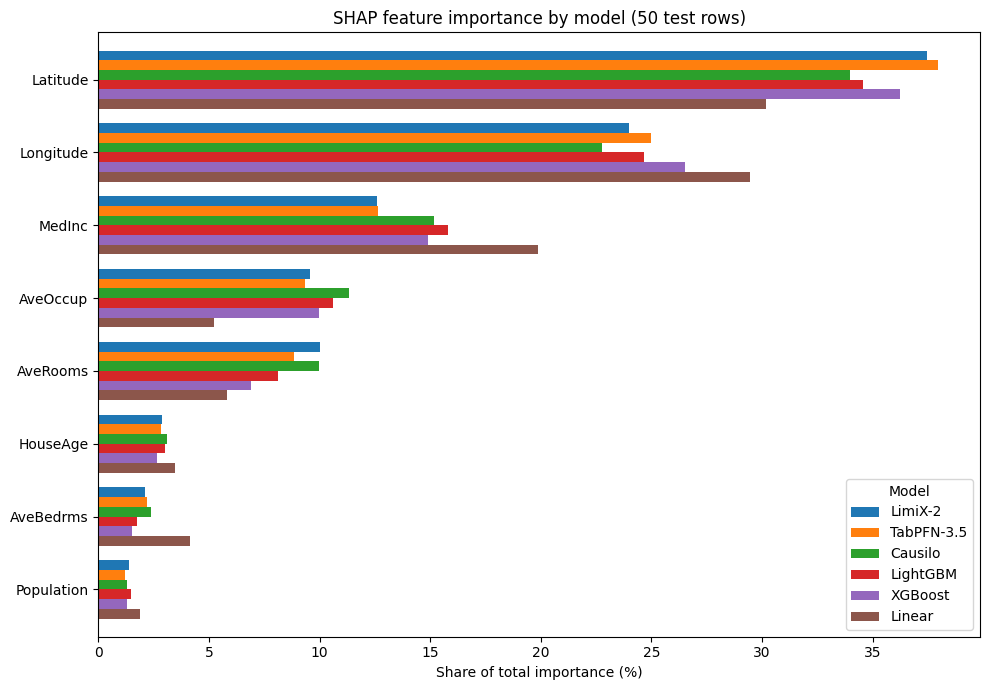

In [26]:
# Global importance = mean |SHAP| per feature
importance = pd.DataFrame(
    {name: np.abs(sv.values).mean(axis=0) for name, sv in shap_values.items()},
    index=X.columns,
)

# Models in the same order as the final comparison, features by average importance
importance = importance[[m for m in df_all.index if m in importance.columns]]
importance = importance.loc[importance.mean(axis=1).sort_values(ascending=False).index]

# % of each model's total importance, to compare models on the same scale
importance_pct = importance / importance.sum() * 100

print("Mean |SHAP| (target units)")
display(importance.round(4))
print("Share of total importance (%)")
display(importance_pct.round(1))

ax = importance_pct.plot.barh(figsize=(10, 7), width=0.8)
ax.invert_yaxis()
ax.set_xlabel("Share of total importance (%)")
ax.set_title(f"SHAP feature importance by model ({N_EXPLAIN} test rows)")
ax.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

### Time of execution

In [27]:
end = time.time()
delta = end - start

hours, rem = divmod(delta, 3600)
minutes, seconds = divmod(rem, 60)

print(f"Total execution time: {int(hours)}h {int(minutes)}m {seconds:.2f}s")

Total execution time: 0h 27m 29.94s
